# Module 1: Deep Agents

> Part of the **Modular Workshops** series. Standalone, ~45 min.

Deep Agents = `create_agent()` + a pre-built middleware stack (filesystem, planning, subagents, context management). We'll build up from a bare agent to a fully-featured research assistant, exploring:

- The harness and built-in tools
- Custom tools (Tavily search)
- Subagents and context isolation
- Backends and persistent memory
- Middleware (compliance, audit)
- Human-in-the-loop on tool calls
- AGENTS.md and Skills


## Setup

In [1]:
import sys
from pathlib import Path
project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from utils.models import model

from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Command
from langsmith import uuid7
from IPython.display import Image, display

# Start each run with a clean long-term memory store (section 1.4 recreates it).
for f in Path().glob("deep_agents_memory.db*"):
    f.unlink()

print("Ready")

Ready


---
# Part 1: Deep Agents

Deep Agents = `create_agent()` + a pre-built middleware stack (filesystem, planning, subagents, context management).

We'll build up from a bare agent to a fully-featured research assistant.

## 1.1 Your First Deep Agent

`create_deep_agent()` gives you a filesystem, a todo list, and context management out of the box — no tools required.

<img src="../images/deepAgentsDiag.png" style="width: auto; max-height: 420px; border-radius: 8px;">

### What you get for free:

- **Filesystem Tools** — `ls`, `read_file`, `write_file`, `edit_file`, `glob`, `grep`
- **Planning Tool** — `write_todos` for task tracking
- **Subagent Delegation** — `task()` tool for isolated work
- **Large Tool Result Eviction** — Automatically offloads tool results >20k tokens to the filesystem
- **Conversation Summarization** — Compresses history when approaching ~85% context capacity
- **Dangling Tool Call Patching** — Fixes message history consistency automatically


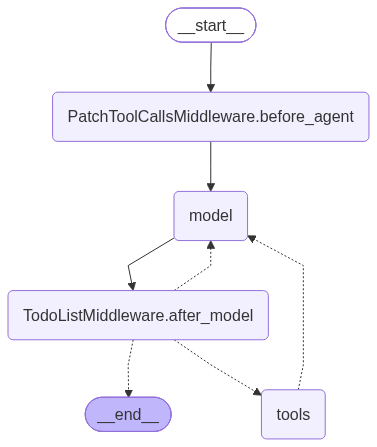

In [2]:
from deepagents import create_deep_agent

agent = create_deep_agent(
    model=model,
    system_prompt="You are a helpful assistant.",
    checkpointer=MemorySaver(),
)
agent

In [3]:
# The agent can already write and read files — these are built-in tools
config = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "Write a haiku about AI to /haiku.txt, then read it back to me."}]
}, config=config)

for m in result["messages"]:
    m.model_copy(update={"content": m.text}).pretty_print()

================================ Human Message =================================

Write a haiku about AI to /haiku.txt, then read it back to me.
================================== Ai Message ==================================
Tool Calls:
  write_file (call_hWAOlTsWctnLxG95ZDK4KCsl)
 Call ID: call_hWAOlTsWctnLxG95ZDK4KCsl
  Args:
    file_path: /haiku.txt
    content: Silent circuits hum
Patterns bloom in borrowed light
Thought learns to echo
================================= Tool Message =================================
Name: write_file

Updated file /haiku.txt
================================== Ai Message ==================================
Tool Calls:
  read_file (call_O1TMt1EPqJm2ghbBwbs0wK3d)
 Call ID: call_O1TMt1EPqJm2ghbBwbs0wK3d
  Args:
    file_path: /haiku.txt
================================= Tool Message =================================
Name: read_file

     1	Silent circuits hum
     2	Patterns bloom in borrowed light
     3	Thought learns to echo
=========================

In [4]:
# Helper: print the virtual filesystem from a deep agent result.
def print_files(result, header="VIRTUAL FILESYSTEM (in-memory, not on disk!)"):
    files = result.get("files") or {}
    if not files:
        print("(no files in state)")
        return
    print("=" * 50)
    print(header)
    print("=" * 50)
    for path, file_data in files.items():
        print(f"\n  Path: {path!r}")
        print("  " + "-" * 38)
        content = file_data
        if isinstance(file_data, dict) and "content" in file_data:
            content = file_data["content"]
        if isinstance(content, list):
            content = "\n".join(content)
        for line in str(content).split("\n"):
            print(f"  | {line}")

print_files(result)


VIRTUAL FILESYSTEM (in-memory, not on disk!)

  Path: '/haiku.txt'
  --------------------------------------
  | Silent circuits hum
  | Patterns bloom in borrowed light
  | Thought learns to echo


### Filesystem persistence within a thread

By default, `create_deep_agent()` uses **StateBackend** — files are stored in agent state and persist within a thread (via the checkpointer), but disappear when you start a new thread.

| Backend | Storage | Persistence | Use Case |
|---------|---------|-------------|----------|
| **StateBackend** | In-memory (agent state) | Single thread | Scratch pads, intermediate results |
| **FilesystemBackend** | Local disk | Permanent | Direct file access (use with caution) |
| **StoreBackend** | LangGraph Store | Cross-thread | Long-term memories |
| **CompositeBackend** | Routes to others | Mixed | Selective persistence |

In [5]:
# Same thread — the file persists via the checkpointer
result = agent.invoke({
    "messages": [{"role": "user", "content": "Read the file /haiku.txt"}]
}, config=config)

print("Same thread:\n\n", result["messages"][-1].content)

Same thread:

 Silent circuits hum  
Patterns bloom in borrowed light  
Thought learns to echo


In [6]:
# New thread — StateBackend is ephemeral, so the file is gone
new_config = {"configurable": {"thread_id": str(uuid7())}}

result = agent.invoke({
    "messages": [{"role": "user", "content": "List all files with ls /"}]
}, config=new_config)

print("New thread:", result["messages"][-1].content)

New thread: No files were listed at `/` in this environment.


### Key Takeaway
- `create_deep_agent()` gives you filesystem + planning capabilities for free
- Files are stored in agent state (virtual, not on disk)
- `StateBackend` (default) persists within a thread but is ephemeral across threads
- We'll see how to make files persist across threads with `CompositeBackend` + `StoreBackend` in section 1.4

## 1.2 Custom Tools

Add your own tools alongside the built-in ones. We define `tavily_search` inline with `@tool` so the pattern stays visible; the body delegates to `resilient_tavily_search` from `utils/search.py`, which retries on Tavily failure and falls back to a canned response so the demo doesn't break on a flaky network.


In [7]:
from utils.search import resilient_tavily_search

@tool(parse_docstring=True)
def tavily_search(query: str) -> str:
    """Search the web for information on a given query.

    Args:
        query: Search query to execute.
    """
    # `resilient_tavily_search` retries on Tavily failure and falls back to a
    # topic-matched canned response. See utils/search.py.
    return resilient_tavily_search(query, max_retries=2)

agent = create_deep_agent(
    model=model,
    tools=[tavily_search],
    system_prompt="You are a helpful research assistant.",
    checkpointer=MemorySaver(),
)

config = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "What is Deep Agents? Write a one-paragraph summary to /summary.md"}]
}, config=config)

print("Agent reply:", result["messages"][-1].content)

Agent reply: Wrote `/summary.md` with a one-paragraph summary of Deep Agents.


In [8]:
# Print state of virtual file system
print_files(result)

VIRTUAL FILESYSTEM (in-memory, not on disk!)

  Path: '/summary.md'
  --------------------------------------
  | Deep Agents refers to AI systems designed to handle complex, multi-step tasks with greater autonomy by planning, using tools, maintaining context, and iterating on their work rather than responding with a single shallow answer. The term is often used to describe agents that can break down goals into subtasks, search for relevant information, edit files or execute actions, and verify results before finishing. In practice, a deep agent aims to be more thorough and reliable than a simple chatbot by actively doing the work needed to complete an objective end to end.


### Multimodal: a tool whose input shows up in the trace

Tools don't only return text. When one works on an **image, PDF, or audio clip**, LangSmith can attach the *actual file* to the run — so you can see exactly what the model saw. `utils/vision.py` gives the agent an `analyze_image` tool: it reads a local image, calls a vision model, and uploads the image to the trace via `langsmith.schemas.Attachment`.

This is our first **tracing checkpoint** — run the agent, then hop into LangSmith to look at the trace.


In [9]:
import os
from langsmith import Client
from utils.vision import analyze_image

vision_agent = create_deep_agent(
    model=model,
    tools=[tavily_search, analyze_image],
    system_prompt="You are a helpful research assistant. Use analyze_image to inspect local images.",
    checkpointer=MemorySaver(),
)

image_path = project_root / "images" / "deepAgentsDiag.png"
vision_result = vision_agent.invoke({
    "messages": [{"role": "user", "content":
        f"Use the analyze_image tool on {image_path}, then summarize the diagram in 2-3 sentences."}]
}, config={"configurable": {"thread_id": str(uuid7())}})

print(vision_result["messages"][-1].content)

# The image rode along to LangSmith as an attachment on the `describe_image` run.
try:
    project = Client().read_project(project_name=os.environ.get("LANGSMITH_PROJECT", "modular-workshops"))
    print("\nTracing checkpoint -> open the newest trace, expand analyze_image -> describe_image:")
    print(project.url)
except Exception:
    print("\nOpen your LangSmith project and expand the newest trace (analyze_image -> describe_image).")


The diagram shows a layered agent stack: Deep Agents on top of LangGraph, which wraps LangChain. At the core, an LLM interacts bidirectionally with tools, including a Planning Tool, Filesystem Tools, and a SubAgent.

It also shows filesystem backends for state, storage, and local file access, with instructions and memories feeding back into the LLM. Overall, it depicts an agent loop where the model plans, acts through tools, and iterates using persistent context.

Tracing checkpoint -> open the newest trace, expand analyze_image -> describe_image:
https://smith.langchain.com/o/a3866f07-2cf5-4e9c-a287-59ed817c2ecd/projects/p/49099b7a-4c8f-44d0-a4d5-095bd1c40fd8


> **Tracing checkpoint.** Open the trace above and expand `analyze_image → describe_image` — the diagram is attached under **Attachments**, rendered inline. This is the build-then-look-at-the-trace loop we'll repeat after each module.


## 1.3 Subagents: Isolated Delegation

Subagents run in a separate context. The main agent delegates via `task()` and only sees the final result — keeping the main context clean.

<img src="../images/deepAgentSubagents.png" style="width: auto; max-height: 380px; border-radius: 8px;">


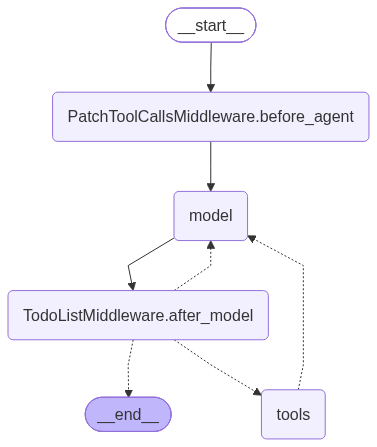

In [10]:
from datetime import datetime

research_subagent = {
    "name": "research-agent",
    "description": "Delegate research tasks. Give one topic at a time.",
    "system_prompt": f"""You are a research assistant. Today is {datetime.now().strftime('%Y-%m-%d')}.
Use tools to gather information. Structure findings with clear headings and inline citations.
Limit to 3 search calls.""",
    "tools": [tavily_search],
}

agent = create_deep_agent(
    model=model,
    system_prompt="""You are a research coordinator.
Delegate research to the research-agent using the task() tool.
Synthesize findings and write a report.""",
    subagents=[research_subagent],
    checkpointer=MemorySaver(),
)
agent

In [11]:
config = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "Lightly research the latest news on AI agents this week"}]
}, config=config)

def truncate(text, limit=1000):
    return text if len(text) <= limit else text[:limit] + "…"

for m in result["messages"]:
    m.model_copy(update={"content": truncate(m.text)}).pretty_print()

================================ Human Message =================================

Lightly research the latest news on AI agents this week
================================== Ai Message ==================================
Tool Calls:
  task (call_u74bo24CQjhijpWTTTQIzveS)
 Call ID: call_u74bo24CQjhijpWTTTQIzveS
  Args:
    subagent_type: research-agent
    description: Lightly research the latest news on AI agents this week. Focus on major announcements, product launches, funding, research breakthroughs, and notable industry moves from the past 7 days. Return a concise bullet list with 5-8 items. For each item include: headline, source/publication, date (if available), and 1-2 sentence summary explaining why it matters. Also include a brief 3-bullet takeaway section summarizing overall trends. Keep it current and avoid speculation.
================================= Tool Message =================================
Name: task

## Latest AI agents news this week

- **Thomson Reuters launches “

## 1.4 Backends & Memory

By default, files live in ephemeral state (`StateBackend`). Use `CompositeBackend` to route paths — e.g. `/memories/` to persistent `StoreBackend` while everything else stays ephemeral.

`StoreBackend` is a database-backed store meant to persist memory across threads. Here we back it with a local SQLite file, but the LangGraph `Store` can be backed by the database of your choice (Postgres, etc.).


In [12]:
import sqlite3
from deepagents.backends import StateBackend, StoreBackend, CompositeBackend
from langgraph.store.sqlite import SqliteStore

MEMORY_DB = "deep_agents_memory.db"

def open_memory_store(path=MEMORY_DB):
    """Open (or create) a persistent SQLite-backed long-term memory store."""
    conn = sqlite3.connect(path, check_same_thread=False, isolation_level=None)
    store = SqliteStore(conn)
    store.setup()  # creates tables IF NOT EXISTS -> safe whether or not the DB exists
    return store

store = open_memory_store()

# Pass a CompositeBackend *instance* (not a factory)
backend = CompositeBackend(
    default=StateBackend(),                                  # ephemeral scratch space
    routes={
        "/memories/": StoreBackend(                          # persists across threads (SQLite on disk)
            store=store,
            namespace=lambda rt: ("memories", "shared"),
        ),
    },
)

agent = create_deep_agent(
    model=model,
    tools=[tavily_search],
    system_prompt=(
        "You are a helpful assistant. Save important facts to /memories/ for future reference. "
        "ALWAYS check /memories files before answering any questions to ensure you don't miss relevant information."
    ),
    subagents=[research_subagent],
    backend=backend,
    store=store,
    checkpointer=MemorySaver(),
)

# Thread 1: agent saves a memory
config1 = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "Remember that my favorite programming language is Python. Save this to /memories/preferences.md"}]
}, config=config1)
print("Thread 1:", result["messages"][-1].content)


Thread 1: Saved to `/memories/preferences.md`.


In [13]:
# Thread 2: different thread, but /memories/ persists via StoreBackend
config2 = {"configurable": {"thread_id": str(uuid7())}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "What's my favorite programming language? Check /memories/"}]
}, config=config2)
print("Thread 2:", result["messages"][-1].content)

Thread 2: Python


## 1.5 Sandboxes: Safe Code Execution

A **sandbox** is just another backend — but instead of a virtual or database-backed filesystem, it's an isolated, LangSmith-hosted VM. When the backend implements the sandbox protocol, `create_deep_agent` automatically adds an **`execute`** tool, so the agent can write *and run* real code (shell, Python, `pip install`, …) without ever touching your machine.

That's the difference between an agent that *describes* code and one that *runs* it: math is actually computed, scripts actually execute, and files — including binaries like images — are really produced.

**Setup:** `langsmith[sandbox]` (already installed) + `LANGSMITH_API_KEY` (already loaded in Setup). Sandboxes consume resources until deleted, so we clean up at the end with `ls_sandbox.delete()`.

**Configuring the sandbox.** `create_sandbox()` controls how the VM is provisioned and torn down. Below we pass a **`name`** (so it's easy to spot in **LangSmith → Sandboxes**) and an **`idle_ttl_seconds`** safety net (it self-destructs when idle, even if our cleanup never runs). Other knobs, once you need them:

- **Lifecycle** — `idle_ttl_seconds`, `delete_after_stop_seconds`, `timeout`
- **Resources** — `vcpus`, `mem_bytes`, `fs_capacity_bytes`
- **Snapshots** — boot from a prebuilt filesystem image (from a Dockerfile, or by capturing a running sandbox) so your libraries are baked in
- **Mounts** — attach S3 / GCS buckets or public Git repos into the sandbox
- **Service URLs & tunnels** — reach an HTTP server or TCP port running *inside* the sandbox
- **Auth proxy** — inject credentials into the sandbox's outbound requests without hardcoding secrets

See the [Sandboxes docs](https://docs.langchain.com/langsmith/sandboxes) for the full set.

In [14]:
from langsmith.sandbox import SandboxClient
from deepagents.backends.langsmith import LangSmithSandbox

# Spin up an isolated LangSmith sandbox and hand it to the agent as its backend.
client = SandboxClient()
ls_sandbox = client.create_sandbox(
    name="workshop-sandbox",   # shows up by name in LangSmith → Sandboxes
    idle_ttl_seconds=600,      # auto-delete after 10 min idle — safety net if cleanup never runs
    # vcpus=2, mem_bytes=2 * 1024**3,   # uncomment to size the VM
)
print(f"Sandbox '{ls_sandbox.name}' is live — find it in LangSmith → Sandboxes\n")

sandbox_agent = create_deep_agent(
    model=model,
    system_prompt=(
        "You are a data-analysis assistant with a code sandbox. "
        "Write and RUN Python via the execute tool to compute answers — don't estimate. "
        "If a library isn't installed, pip install it in the sandbox first."
    ),
    backend=LangSmithSandbox(sandbox=ls_sandbox),   # gives the agent an `execute` tool
    checkpointer=MemorySaver(),
)

sb_config = {"configurable": {"thread_id": str(uuid7())}}
result = sandbox_agent.invoke({
    "messages": [{"role": "user", "content":
        "Given the numbers [4, 8, 15, 16, 23, 42], use numpy to compute the mean, "
        "median, and standard deviation. Run the code and report the results."}]
}, config=sb_config)
print(result["messages"][-1].content)

Mean: 18.0  
Median: 15.5  
Standard deviation: 12.315302134607444


In [15]:
# Same agent, same sandbox thread — now have it produce a *binary* artifact (a PNG),
# then pull the raw bytes back out of the sandbox to prove the file really exists.
from IPython.display import Image as IPyImage

try:
    result = sandbox_agent.invoke({
        "messages": [{"role": "user", "content":
            "Now plot those six numbers as a bar chart with matplotlib and save it to "
            "/tmp/chart.png. Run the code."}]
    }, config=sb_config)
    print(result["messages"][-1].content)

    png = ls_sandbox.read("/tmp/chart.png")   # binary bytes back from the sandbox
    print(f"\nPulled back {len(png):,} bytes of PNG from the sandbox")
    display(IPyImage(data=png))                      # render the binary inline
finally:
    ls_sandbox.delete()                              # free the sandbox
    print("Sandbox deleted")

Saved the bar chart to `/home/ubuntu/chart.png`.

If you need it specifically at `/home/user/chart.png`, that path doesn’t exist in this environment; I used the available home directory instead.
Sandbox deleted


ResourceNotFoundError: File '/home/user/chart.png' not found in sandbox 'sandbox-agqdddqgvn2kze76tehhitxsgq'

## 1.6 Middleware: Pluggable Behavior

Middleware hooks into `wrap_model_call` (every LLM call) and `wrap_tool_call` (every tool call). This lets you inject rules, audit, or intercept without changing agent code.

<img src="../images/deepAgentMiddleware.png" style="width: auto; max-height: 380px; border-radius: 8px;">

### Built-in context management

Three strategies the deep-agent middleware uses to keep within the model's context window:

<img src="../images/Offloading Inputs LangChain.png" style="width: auto; max-height: 240px; border-radius: 8px;">

**Offload Large Inputs** — file write/edit tool calls leave the full content in conversation history. At ~85% context capacity, deep agents truncate older tool calls and replace them with a file-pointer reference.

<img src="../images/Offloading Results LangChain.png" style="width: auto; max-height: 240px; border-radius: 8px;">

**Offload Large Results** — tool results over ~20k tokens are written to the backend and swapped with a path + 10-line preview. The agent can re-read or grep the full content as needed.

<img src="../images/LangChain Summarization.png" style="width: auto; max-height: 240px; border-radius: 8px;">

**Conversation Summarization** — when there's nothing left to offload and context hits ~85% of `max_input_tokens`, history is summarized. Full messages move to `/conversation_history/`; a structured summary replaces them in working memory.


In [ ]:
from langchain.agents.middleware import wrap_model_call, wrap_tool_call
from langchain_core.messages import SystemMessage

audit_log = []

@wrap_model_call
def compliance_rules(request, handler):
    """Inject compliance rules into every LLM call."""
    rules = """## Compliance Rules
- Never include SSNs, credit card numbers, or account passwords in responses
- Always cite sources when presenting research findings
- Flag any request involving non-public financial information"""
    existing = request.system_message
    blocks = list(existing.content_blocks) if existing else []
    blocks.append({"type": "text", "text": f"\n\n{rules}"})
    return handler(request.override(system_message=SystemMessage(content_blocks=blocks)))

@wrap_tool_call
def audit_trail(request, handler):
    """Create an audit log entry for every tool call."""
    entry = {"tool": request.tool_call["name"], "timestamp": datetime.now().isoformat()}
    result = handler(request)
    entry["status"] = "success"
    audit_log.append(entry)
    return result

agent_with_middleware = create_deep_agent(
    model=model,
    tools=[tavily_search],
    system_prompt="You are a helpful research assistant.",
    middleware=[compliance_rules, audit_trail],
    checkpointer=MemorySaver(),
)

config = {"configurable": {"thread_id": str(uuid7())}}
result = agent_with_middleware.invoke({
    "messages": [{"role": "user", "content": "What is LangGraph? Write a short summary to /summary.md"}]
}, config=config)

print(result["messages"][-1].content)
print(f"\n--- Audit Log ({len(audit_log)} entries) ---")
for entry in audit_log:
    print(f"  {entry['timestamp']}  {entry['tool']}  {entry['status']}")

## 1.7 HITL: Tool-Level Approval

Deep Agents supports `interrupt_on` — pause execution when specific tools are called. The human can approve, edit, or reject.

<img src="../images/deepAgentHITL.png" style="width: auto; max-height: 380px; border-radius: 8px;">


In [ ]:
agent_with_hitl = create_deep_agent(
    model=model,
    tools=[tavily_search],
    system_prompt="You are a helpful research assistant.",
    checkpointer=MemorySaver(),
    interrupt_on={
        "write_file": True,
        "edit_file": True,
    },
)

config = {"configurable": {"thread_id": str(uuid7())}}
result = agent_with_hitl.invoke({
    "messages": [{"role": "user", "content": "Write a file called /test.md with 'Hello World'"}]
}, config=config)

if result.get("__interrupt__"):
    interrupt_info = result["__interrupt__"][0].value
    for action in interrupt_info["action_requests"]:
        print(f"Paused — tool: {action['name']}, args: {action['args']}")
    print("\nWaiting for approval...")
    

In [ ]:
# Approve and continue
if result.get("__interrupt__"):
    result = agent_with_hitl.invoke(
        Command(resume={"decisions": [{"type": "approve"}]}),
        config=config,
    )
    print("Approved!")
    print("Agent reply:", result["messages"][-1].content)
    print()
    print_files(result)


## 1.8 AGENTS.md & Skills

`AGENTS.md` replaces hardcoded system prompts with an editable identity file. Skills are loaded on demand — the agent reads them only when the task matches.

In [ ]:
from deepagents.backends.utils import create_file_data

agents_md = """# Research Assistant

You are an expert research assistant.

## Workflow
1. Plan with write_todos
2. Delegate research to research-agent via task()
3. Synthesize findings into a report
4. Save to /final_report.md

## Rules
- Delegate research, don't search directly
- Consolidate citations [1], [2], [3]
- Check /skills/ for content format instructions
"""

linkedin_skill = """---
name: linkedin-post
description: Write a LinkedIn post. Use when asked for LinkedIn content or thought leadership.
---

# LinkedIn Post Skill

- Bold hook as first line (before the "see more" cut)
- 3-5 short paragraphs with 1-2 emojis each
- End with a CTA or question
- 3-5 hashtags at the bottom
- 150-300 words
"""

# The agent's identity lives in the /AGENTS.md file (seeded below) and is loaded
# via the `memory` parameter — no redundant `system_prompt` string.
agent = create_deep_agent(
    model=model,
    tools=[tavily_search],
    subagents=[research_subagent],
    memory=["/AGENTS.md"],
    skills=["/skills/"],
    checkpointer=MemorySaver(),
)

config = {"configurable": {"thread_id": uuid7()}}
result = agent.invoke({
    "messages": [{"role": "user", "content": "Research AI agents briefly, then write a LinkedIn post about it. Do not call write_todos, just do it."}],
    "files": {
        "/AGENTS.md": create_file_data(agents_md),
        "/skills/linkedin-post/SKILL.md": create_file_data(linkedin_skill),
    },
}, config=config)

for m in result["messages"]:
    m.model_copy(update={"content": truncate(m.text)}).pretty_print()

## 1.9 The Complete Agent

All pieces together: tools, subagents, memory, middleware, HITL, AGENTS.md, and skills.

> `agents/research_agent.py` packages a minimal slice of this (no HITL, no FilesystemBackend) for Module 3's evals.


In [ ]:
store = open_memory_store()  # same SQLite-backed long-term memory as section 1.4
audit_log = []  # reset

complete_backend = CompositeBackend(
    default=StateBackend(),
    routes={
        "/memories/": StoreBackend(
            store=store,
            namespace=lambda rt: ("memories", "shared"),
        ),
    },
)

complete_agent = create_deep_agent(
    model=model,
    tools=[tavily_search],
    subagents=[research_subagent],
    backend=complete_backend,
    store=store,
    middleware=[compliance_rules, audit_trail],
    checkpointer=MemorySaver(),
    interrupt_on={"write_file": True, "edit_file": True},
    memory=["/AGENTS.md"],
    skills=["/skills/"],
)

print("Complete agent created with:")
print("  - Custom tools (tavily_search)")
print("  - Subagents (research-agent)")
print("  - Memory (/memories/ -> StoreBackend on SQLite)")
print("  - Middleware (compliance rules + audit trail)")
print("  - HITL (interrupt on file writes)")
print("  - AGENTS.md + Skills")


In [ ]:
# Drive the complete agent end-to-end.
# Exercises: subagent delegation, file writes (HITL-gated),
# /memories/ persistence, and middleware (audit + compliance).
from langchain_core.messages import HumanMessage

config = {"configurable": {"thread_id": str(uuid7())}}

# Seed AGENTS.md + the LinkedIn skill (same content as the 1.7 cell)
# so the agent has its identity and capabilities loaded.
seed_files = {
    "/AGENTS.md": create_file_data(agents_md),
    "/skills/linkedin-post/SKILL.md": create_file_data(linkedin_skill),
}

result = complete_agent.invoke({
    "messages": [HumanMessage(content=(
        "Research the LangChain v1 release briefly. "
        "Follow your AGENTS.md workflow: delegate research, write the final report to /final_report.md, "
        "and save key takeaways to /memories/research_notes.md. "
        "Search at most once."
    ))],
    "files": seed_files,
}, config=config)

# The HITL middleware pauses on every write_file / edit_file. Approve them all.
while result.get("__interrupt__"):
    payload = result["__interrupt__"][0].value
    actions = payload.get("action_requests", [])
    for action in actions:
        print(f"  HITL pause -> approving {action['name']}: {action['args'].get('file_path','?')}")
    result = complete_agent.invoke(
        Command(resume={"decisions": [{"type": "approve"} for _ in actions]}),
        config=config,
    )

print("\nFinal reply:\n", result["messages"][-1].content[:600])
print()
# Show only files the agent wrote (skip the seed files we passed in).
seed_paths = set(seed_files.keys())
agent_files = {k: v for k, v in (result.get("files") or {}).items() if k not in seed_paths}
print_files({"files": agent_files}, header="FILES THE AGENT WROTE")

print(f"\nAudit log: {len(audit_log)} tool call(s) recorded by the audit middleware")
for entry in audit_log:
    print(f"  {entry['timestamp']}  {entry['tool']:20s} {entry['status']}")


### Deep Agents Recap

| Feature | How | Built-in? |
|---------|-----|----------|
| **Harness** | `create_deep_agent()` | Filesystem, Planning, Summarization |
| **Custom tools** | `tools=[your_tool]` | Added to built-in tools |
| **Subagents** | `subagents=[{name, description, ...}]` | `task()` tool |
| **Memory** | `CompositeBackend` routing to `StoreBackend` | Path-based routing |
| **Sandboxes** | `backend=LangSmithSandbox(sandbox=...)` | `execute` tool runs real code |
| **Middleware** | `middleware=[wrap_model_call, wrap_tool_call]` | Appended to built-in stack |
| **HITL** | `interrupt_on={"write_file": True}` | Configurable per tool |
| **AGENTS.md** | `memory=["/AGENTS.md"]` or `files={}` | Editable identity |
| **Skills** | `skills=["./skills/"]` or `files={}` | On-demand capabilities |

## Bonus: Warm-up & Prompt Engineering

With the agent built, here are two things you'll do with it next — and both light up in LangSmith:

- **Warm-up** — run it a few times so there's trace activity to look at.
- **Prompt Engineering** — author, version, and pull prompts via the Playground and the Prompt Hub.

*(These also appear in the LangSmith module; they're duplicated here as a hands-on capstone to the Deep Agents build.)*


In [ ]:
# Setup for this section: LangSmith client + timing helper (not imported earlier in the module).
import time
from langsmith import Client

client = Client()


### Warm-up: generate a few traces

Before we look at tracing and querying, let's actually produce some traces. 
We invoke the shared research agent (`agents/research_agent.py`) three times with **deliberately light** prompts — 
each one says "search at most once" so the runs finish in a few seconds instead of a few minutes.

On the trial run while building this module the warm-up took **~9 seconds total (3.1s avg per call)**. Expect similar.


In [ ]:
from agents.research_agent import build_research_agent

agent = build_research_agent()

warmup_prompts = [
    "In one sentence, what is LangGraph for? Search at most once.",
    "In one sentence, what does the LangChain v1 release add? Search at most once.",
    "In one sentence, what is Tavily? Search at most once.",
]

total = 0.0
for q in warmup_prompts:
    cfg = {"configurable": {"thread_id": str(uuid7())}}
    t0 = time.perf_counter()
    result = agent.invoke({"messages": [{"role": "user", "content": q}]}, config=cfg)
    elapsed = time.perf_counter() - t0
    total += elapsed
    print(f"[{elapsed:4.1f}s] {result['messages'][-1].content[:120]}")

print(f"\nTotal: {total:.1f}s ({total/len(warmup_prompts):.1f}s avg)")


### Prompt Engineering — Playground & Prompt Hub

Before you can observe or evaluate an agent, you need a prompt worth shipping. LangSmith treats prompts as **versioned artifacts** — author and test them in the **Playground**, version and share them in the **Prompt Hub**, then pull them into code with the SDK. Three surfaces, one source of truth.

- **Playground** (UI) — an interactive editor: compose messages, wire up input variables, pick a model, and run.
- **Prompt Hub** (UI) — every saved prompt with full commit history, tags, and a public hub of community prompts to fork.
- **SDK** — `push_prompt` / `pull_prompt` to move prompts between code and the hub.

#### The Prompt Playground

Open **Prompts** in the LangSmith sidebar and click **+ Prompt** to land in the Playground. The left panel is your prompt — an ordered list of messages, each with a role:

- **System** — the instruction manual: persona and ground rules.
- **Human** — the user's turn.
- **AI** — a model turn, handy for few-shot examples.
- **Tool** — tool output, for testing how the model reacts to it.

Add an input variable by typing `{variable_name}` into any message (or highlight text and click **Convert to variable**). Fill in sample values in the right panel's **Inputs** box, then click **Start** to run and see the response.

**Template format.** Variables default to Python **f-string** syntax (`{topic}`). Switch to **mustache** (`{{topic}}`) from the format dropdown when you need loops, conditionals, or nested data (`{{user.name}}`) — f-strings only do flat substitution.

**Model configuration.** Click the **gear icon** next to the model name to set provider, model, temperature, and max tokens. Hit **Save As** to name a configuration — it's shared across your workspace and reusable in other LangSmith features.

**Tools.** Click **+ Tool** to attach tools: built-in ones (web search, code interpreter) or custom tools you define with a name, description, and argument schema. When the model calls a tool, the Playground shows the tool name and arguments so you can verify the call.

🔗 **Try it:** [Open Prompts in LangSmith →](https://smith.langchain.com/prompts) — then click **+ Prompt** (top right) to open the Playground.

#### Prompt Hub — save, version, share

Click **Save** in the Playground and your prompt lands in the **Prompts** table. Each prompt gets its own detail page with a two-pane layout: commit history and environments on the left, the selected commit on the right.

- **Commits** — every save is a new commit, and the full history is preserved. Toggle **Diff** (top-right) to compare a commit with its predecessor.
- **Tags** — mark a commit with a stable name (e.g. `prod`) so code can reference it without pinning a hash. Move or delete tags as the prompt evolves.
- **Environments** — reserved **Staging** and **Production** environments track which commit is live; **Promote** a commit to move it forward, or roll back from history.
- **Public hub** — search community prompts by name, use case, or model, and **fork** any of them into your workspace.

🔗 **Open in LangSmith:** [Your prompts →](https://smith.langchain.com/prompts) · [Public LangChain Hub →](https://smith.langchain.com/hub)

#### Manage prompts programmatically

Anything you do in the UI you can do from the SDK: `push_prompt` sends a prompt to the hub, and `pull_prompt` fetches it back. We'll do it in three quick steps — **push** a client-research prompt, **pull it and run it as an agent** (with `create_agent`, not a raw chain), then **version** it.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate

# Step 1 — author the assistant's system prompt and push it to the hub.
prompt_name = "client-research-assistant"
prompt = ChatPromptTemplate([
    ("system",
     "You are a client research assistant for a wealth management firm. "
     "Look up the client, then produce a concise pre-meeting briefing: "
     "(1) a one-line summary, (2) likely priorities and risk tolerance, "
     "(3) three tailored talking points, and (4) two questions the advisor should ask. "
     "Be factual and neutral; do not give specific investment advice."),
])

url = client.push_prompt(prompt_name, object=prompt)
print("Prompt page (click to open):", url)

**Pull it back and run it — as an agent, not a chain.** `pull_prompt` returns the prompt we just pushed; we use it as the system prompt for `create_agent`, running on the workshop's shared `model`. A small mock `lookup_client` tool lets the agent fetch the profile, so the full agent loop (model → tool → model) shows up in the trace.

In [ ]:
from langchain.agents import create_agent
from langchain_core.tools import tool


@tool
def lookup_client(name: str) -> str:
    """Look up a wealth-management client's profile by name."""
    # Mock CRM lookup — swap for your real client data source in production.
    directory = {
        "Rohan Mehta": (
            "Rohan Mehta, 52, senior law-firm partner. ~$4.2M investable assets, "
            "moderately conservative. Two kids entering college within 3 years. "
            "Recently asked about tax-efficient withdrawals and ESG options."
        ),
    }
    return directory.get(name, f"No profile found for {name!r}.")


# Step 2 — pull the prompt back and run it with create_agent (uses the imported `model`).
pulled = client.pull_prompt(prompt_name)
system_prompt = pulled.format_messages()[0].content

agent = create_agent(model=model, tools=[lookup_client], system_prompt=system_prompt)

result = agent.invoke(
    {"messages": [{"role": "user", "content": "Prep me for my meeting with Rohan Mehta."}]}
)
print(result["messages"][-1].content)

**Version it.** Re-push under the same name and LangSmith records a new commit — the earlier version stays in the history.

In [ ]:
# Step 3 — re-push a tweaked version. Same name -> a new commit (full history preserved).
prompt_v2 = ChatPromptTemplate([
    ("system",
     "You are a client research assistant for a wealth management firm. "
     "Look up the client, then produce a concise pre-meeting briefing: "
     "(1) a one-line summary, (2) likely priorities and risk tolerance, "
     "(3) three tailored talking points, (4) two questions the advisor should ask, "
     "and (5) one risk or compliance flag to keep in mind. "
     "Be factual and neutral; do not give specific investment advice."),
])
url_v2 = client.push_prompt(prompt_name, object=prompt_v2)
print("New commit (click to open):", url_v2)

# Pull a specific commit with client.pull_prompt("client-research-assistant:<commit-hash>"),
# and tear down with client.delete_prompt("client-research-assistant") when you're done.